# E.3 Add time without hiding uncertainty

Three Neolithic dogs had 2, 2, and 3 *AMY2B* copies. None had the extreme expansion common in many modern dogs. Does zero of three mean that the historical frequency was zero?

Ancient genomes observe an earlier time point. A small ancient sample still leaves broad uncertainty about the population frequency at that time.


## Model outline and expected result

Call more than six copies an extreme expansion, following the contrast used in Botigué et al. Let $f_{ancient}$ be its frequency in an idealized ancient population and $K$ the number observed among three independently sampled dogs.

$$
K\mid f_{ancient}\sim\operatorname{Binomial}(3,f_{ancient}),\qquad
P(K=0\mid f_{ancient})=(1-f_{ancient})^3.
$$

We expect the likelihood to be largest at zero but broad. The one-sided 95% upper bound should be far above zero.


In [1]:
library(hpgR)

ancient_copy_number <- c(CTC = 2, HXH = 2, NGD = 3)
extreme <- ancient_copy_number > 6
n <- length(extreme)
K <- sum(extreme)
upper_95 <- zeroCountUpperBound(n)

stopifnot(K == 0, n == 3)
c(observed_extreme = K, sampled_dogs = n, upper_95 = upper_95)

observed_extreme     sampled_dogs         upper_95 
       0.0000000        3.0000000        0.6315969

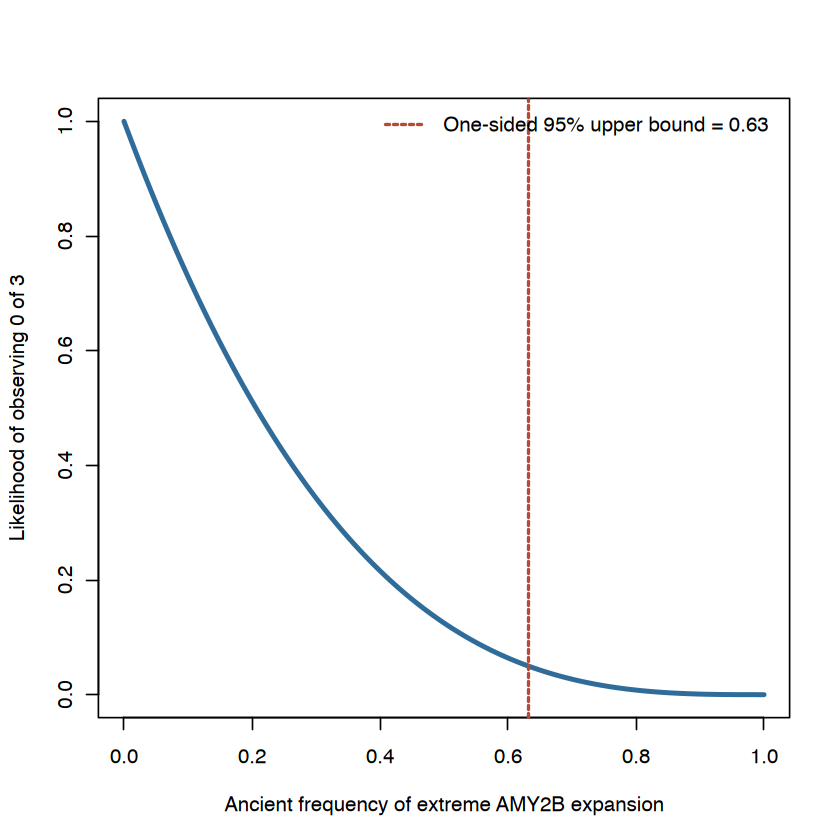

In [2]:
frequency_grid <- seq(0, 1, length.out = 501)
likelihood <- dbinom(K, size = n, prob = frequency_grid)

plot(frequency_grid, likelihood, type = 'l', lwd = 3, col = '#306C9A',
     xlab = 'Ancient frequency of extreme AMY2B expansion',
     ylab = 'Likelihood of observing 0 of 3')
abline(v = upper_95, col = '#B44A3A', lty = 2, lwd = 2)
legend('topright', legend = sprintf('One-sided 95%% upper bound = %.2f', upper_95),
       col = '#B44A3A', lty = 2, lwd = 2, bty = 'n')

The likelihood decreases as the proposed ancient frequency rises, but three observations cannot make it narrow. The exact one-sided upper bound is about 0.63.

The same zero becomes more informative when the sample is larger.


In [3]:
sample_size <- c(3, 10, 30, 100)
upper_if_zero <- zeroCountUpperBound(sample_size)
data.frame(sample_size = sample_size, upper_95 = round(upper_if_zero, 3))

sample_size,upper_95
<dbl>,<dbl>
3,0.632
10,0.259
30,0.095
100,0.030


## What to remember

The three genomes show that extreme *AMY2B* expansion was not required in those sampled Neolithic dogs. They do not show that its population frequency was zero. Ancient DNA adds a time point; the sampling model determines the precision. Archaeological specimens are also opportunistic rather than a random sample from one ancient population, so the binomial result is an idealized bound, not a final historical estimate.

**Sources.** Botigué et al. (2017), *Nature Communications*, doi:10.1038/ncomms16082; Arendt et al. (2016), *Heredity*, doi:10.1038/hdy.2016.48. The threshold and binomial model reproduce the lecture's conceptual comparison; they do not reproduce the papers' full ancient-DNA analysis.
